# 02 · 랜덤 포레스트 학습·검증·최종 테스트 — 간소화 최종본
**실행 코드 8셀**. 기존 49셀의 복구·중복 진단을 통합하고, 없었던 최종 평가·저장을 추가했습니다.

## 실험 설계
- 랜덤 포레스트 단일 모델: 300 trees, max_depth=20, min_samples_leaf=2, class_weight=balanced, seed=42.
- 학습은 기존 약 99,998행/116명 표본을 유지합니다. 전체 학습 분할의 1,075만 행을 모두 학습하는 실험이 아닙니다.
- 입력은 기존 6개 변수. **시간차를 사용자+공유 배너 기준으로 학습·검증·테스트 모두 재계산**하여 기존 불일치를 수정합니다.
- 학습/검증 변조는 저장된 자료를 재사용합니다. 테스트 변조는 학습 원본의 아이템 후보만 사용하여 독립 고정 시드로 생성합니다.
- 각 split의 합성 변조: 3성→5성 무기 1,000건 / 다른 4성 캐릭터명으로 변경 500건.
- 검증 F1 최대 임계값을 고정한 다음 미사용 테스트 사용자 전체를 평가합니다. 테스트로 튜닝하지 않습니다.
- 정상은 정상 **후보**, 변조는 **합성 라벨**입니다. 실제 해킹 탐지율이나 변조 예방 성능으로 과장하지 않습니다.

## 자동 생성되는 논문용 결과
| 파일 | 내용 |
|---|---|
| performance_metrics.csv | 정밀도, 재현율, F1, 정확도, 균형정확도, FPR, specificity, AP, 사다리꼴 PR-AUC, ROC-AUC, TN/FP/FN/TP |
| performance_by_tamper_type.csv | 정상 오탐률 및 두 변조 유형의 재현율 |
| test_user_bootstrap_ci95.csv | 고정 모델의 주요 판정 지표에 대한 사용자 단위 95% CI (1,000회) |
| always_normal_baseline.csv | 모두 정상으로 판정하는 단순 기준과 비교 |
| test_evaluation.png / .svg | PR 곡선, ROC 곡선, 혼동행렬 |
| feature_importance_encoded.csv | 인코딩 변수 중요도 (인과적 설명이 아님) |
| paper_results_summary.md | 실행한 수치가 채워지는 논문용 요약과 한계 |
| final_model_bundle.joblib | 전처리 파이프라인, RF, 판정 임계값, 번역 사전·특징 정보 |
| experiment_manifest.json | 파라미터, 데이터 파일 정보, 라이브러리 버전, 학습 시간 |
| validation_scores.parquet / test_scores.parquet | 결과 재검토용 소형 점수표 |

모델을 외부에서 사용할 때는 `feature_spec.json`과 이 노트북의 `prepare_history()`와 동일한 처리로 과거 이력의 시간차를 만든 뒤, `FEATURES`를 파이프라인에 넣고 저장된 threshold로 판정해야 합니다.
실제 미래 로그 한 행만으로 시간차를 계산할 수 없으므로 해당 사용자의 이전 이력이 필요합니다.

## 실행 전
1. **런타임 → 런타임 유형 변경 → CPU**를 선택합니다. GPU는 필요하지 않습니다.
2. 기존의 긴 노트북 런타임은 **연결 해제 및 삭제**하고, 이 노트북을 새 런타임에서 실행합니다.
3. 첫 셀의 `BASE`는 기존 Google Drive 경로입니다. 폴더를 옮겼다면 이 한 곳만 바꿉니다.
4. 위에서 아래로 실행합니다. 빨간 오류가 나오면 중단하고 그 오류를 확인합니다. 오류를 무시하고 아래 셀을 실행하지 않습니다.
5. 실행 결과는 Drive의 `capstonedata2/capstone_final_v2/`에 저장됩니다. 기존 원본·기존 모델 파일은 덮어쓰지 않습니다.

서버 RAM 사용을 줄이기 위해 65,536행씩 읽고, 모델은 CPU 2개와 희소 인코딩을 사용합니다.
브라우저에는 짧은 표와 정적 그림만 출력합니다. Colab 연산은 원격 서버에서 수행되며, 이 최적화가 노트북 화면 깜빡임의 하드웨어/브라우저 원인까지 해결한다고 보장하지는 않습니다.
40분 내 완료를 목표로 구성했지만 Drive 속도·런타임에 따라 달라집니다. 대규모 탐색/교차검증은 수행하지 않습니다.


## 1. 환경·경로 설정
새 CPU 런타임에서 시작하세요. 기존 파일이 모두 있으면 01번 재실행은 필요 없습니다.

In [1]:
# CPU 일반 런타임에서 실행. 새 런타임에서 위에서 아래로 실행하세요.
import os
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[key] = '2'
import importlib.util, subprocess, sys
packages = {'pyarrow':'pyarrow', 'sklearn':'scikit-learn', 'scipy':'scipy',
            'pandas':'pandas', 'numpy':'numpy', 'matplotlib':'matplotlib', 'joblib':'joblib'}
missing = [v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
from pathlib import Path
if not Path('/content/drive/MyDrive').exists():
    from google.colab import drive
    drive.mount('/content/drive')
import json, gc, time, hashlib, shutil, platform
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
BASE = Path('/content/drive/MyDrive/캡스톤 2/capstonedata2')
PROCESSED = BASE / 'genshin_processed'
DATA = BASE / 'rf_model_data'
OUT = BASE / 'capstone_final_v2'
OUT.mkdir(parents=True, exist_ok=True)
BATCH = 65536
SEED = 42
BANNER = {'100':'beginner', '200':'standard', '301':'character_event',
          '302':'weapon_event', '400':'character_event'}
KEY = ['user_id', 'gacha_id']
RAW = KEY + ['name_zh','name_ko','gacha_type','item_type','rank_type','gacha_time']

def save_json(obj, path):
    tmp = Path(str(path)+'.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    os.replace(tmp, path)

def fingerprint(path):
    p = Path(path)
    return {'path':str(p), 'bytes':p.stat().st_size, 'mtime_ns':p.stat().st_mtime_ns}

def canonical(df):
    df = df.copy()
    for c in KEY:
        assert df[c].notna().all(), f'{c} 결측'
        df[c] = df[c].astype(str).str.strip()
        assert df[c].ne('').all(), f'{c} 빈 값'
    df['gacha_type'] = pd.to_numeric(df['gacha_type'], errors='raise').astype('int16').astype(str)
    for c in ['item_type','rank_type']:
        df[c] = pd.to_numeric(df[c], errors='raise').astype('int8')
    df['gacha_time'] = pd.to_datetime(df['gacha_time'], errors='raise')
    for c in ['name_zh','name_ko']:
        df[c] = df[c].astype('string')
    assert df[RAW].notna().all().all(), '원본 필수 열 결측'
    assert df['gacha_type'].isin(BANNER).all(), '알 수 없는 배너'
    assert df['item_type'].isin([0,1]).all() and df['rank_type'].isin([3,4,5]).all()
    return df

print('준비 완료 | 묶음 크기:', BATCH, '| 결과 폴더:', OUT)


Mounted at /content/drive
준비 완료 | 묶음 크기: 65536 | 결과 폴더: /content/drive/MyDrive/캡스톤 2/capstonedata2/capstone_final_v2


## 2. 실험 설정·학습 원본 로드
CPU가 느리거나 메모리가 부족하면 N_JOBS=1, BATCH=32768, PREDICT_BATCH=8192로 줄일 수 있습니다. 연구 설정은 테스트 결과를 본 뒤 바꾸지 마세요.

In [2]:
import sklearn, scipy, joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
                             roc_curve, auc, confusion_matrix)
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
N_JOBS = 2
N_TREES = 300
PREDICT_BATCH = 16384
N_BUCKETS = 16
BOOTSTRAPS = 1000
N_RANK, N_CHARACTER = 1000, 500
TEST_SEED = 20261101
RUN = OUT/'random_forest_v2'
RUN.mkdir(parents=True,exist_ok=True)
CAT = ['gacha_type','name_ko','banner_group']
NUM = ['item_type','rank_type','time_diff_seconds']
FEATURES = CAT+NUM
assert not set(FEATURES)&{'user_id','gacha_id','label','tamper_type'}
required = ['rf_normal_candidates.parquet','rf_split_users.csv','rf_tampered_item_raw.parquet',
            'rf_tampered_character_raw.parquet','rf_validation_raw.parquet',
            'rf_validation_tampered.parquet','rf_test_raw.parquet']
missing = [f for f in required if not (DATA/f).exists()]
assert not missing, f'필요 파일 없음: {missing}. 01번 및 기존 합성 변조 저장 파일을 확인하세요.'
split = pd.read_csv(DATA/'rf_split_users.csv',dtype={'user_id':str})
assert not split['user_id'].duplicated().any()
assert set(split['split'])=={'train','val','test'}
sets={s:set(split.loc[split['split'].eq(s),'user_id']) for s in ['train','val','test']}
assert sets['train'].isdisjoint(sets['val']) and sets['train'].isdisjoint(sets['test']) and sets['val'].isdisjoint(sets['test'])
normal=canonical(pd.read_parquet(DATA/'rf_normal_candidates.parquet',columns=RAW))
assert not normal.duplicated(KEY).any() and set(normal['user_id']).issubset(sets['train'])
# 학습 자료에 저장된 번역을 공통 적용. 평가 데이터로 사전을 학습하지 않습니다.
lookup=normal[['name_zh','name_ko']].drop_duplicates()
assert lookup.groupby('name_zh')['name_ko'].nunique().max()==1
NAME_MAP=dict(zip(lookup['name_zh'],lookup['name_ko']))
normal['name_ko']=normal['name_zh'].map(NAME_MAP).fillna(normal['name_ko']).astype('string')
weapon_pool=normal.loc[normal['rank_type'].eq(5)&normal['item_type'].eq(1),['name_zh','name_ko']].drop_duplicates('name_ko').sort_values('name_ko').reset_index(drop=True)
char_pool=normal.loc[normal['rank_type'].eq(4)&normal['item_type'].eq(0),['name_zh','name_ko']].drop_duplicates('name_ko').sort_values('name_ko').reset_index(drop=True)
assert len(weapon_pool)>0 and len(char_pool)>1
sources={f:fingerprint(DATA/f) for f in required}
print('학습 원본:',len(normal),'행 /',normal['user_id'].nunique(),'명 | 희소 인코딩 / CPU 2개')


학습 원본: 99998 행 / 116 명 | 희소 인코딩 / CPU 2개


## 3. 공통 처리 함수
사용자 전체 이력을 버킷으로 묶어 시간차 계산의 청크 경계 오류를 막습니다. 출력이 없는 것이 정상입니다.

In [3]:
def prepare_history(raw, replacements):
    """원본 식별자로 교체하고 모든 split에 동일한 과거 시간차를 계산합니다."""
    d=canonical(raw[RAW]).reset_index(drop=True)
    assert not d.duplicated(KEY).any(), '중복 식별자'
    d['name_ko']=d['name_zh'].map(NAME_MAP).fillna(d['name_ko']).astype('string')
    d['label']=np.int8(0);d['tamper_type']='normal'
    if len(replacements):
        r=canonical(replacements[RAW]).reset_index(drop=True)
        r['tamper_type']=replacements['tamper_type'].to_numpy()
        assert not r.duplicated(KEY).any()
        keys=pd.MultiIndex.from_frame(d[KEY]); rkeys=pd.MultiIndex.from_frame(r[KEY])
        pos=keys.get_indexer(rkeys); assert (pos>=0).all(), '원본에 없는 변조 키'
        for c in ['gacha_type','gacha_time','item_type']:
            assert np.array_equal(d.iloc[pos][c].to_numpy(),r[c].to_numpy()), f'의도하지 않은 {c} 변경'
        r['name_ko']=r['name_zh'].map(NAME_MAP).fillna(r['name_ko']).astype('string')
        assert (d.iloc[pos]['name_ko'].to_numpy()!=r['name_ko'].to_numpy()).all(), '실제 이름 변경 없음'
        a=r['tamper_type'].eq('item_and_rank_change').to_numpy()
        b=r['tamper_type'].eq('character_name_change').to_numpy()
        assert (a|b).all()
        assert (d.iloc[pos[a]]['rank_type'].eq(3)&d.iloc[pos[a]]['item_type'].eq(1)).all()
        assert r.loc[a,'rank_type'].eq(5).all()
        assert (d.iloc[pos[b]]['rank_type'].eq(4)&d.iloc[pos[b]]['item_type'].eq(0)).all()
        assert r.loc[b,'rank_type'].eq(4).all()
        for c in ['name_zh','name_ko','rank_type','tamper_type']:
            d.loc[pos,c]=r[c].to_numpy()
        d.loc[pos,'label']=np.int8(1)
    d['banner_group']=d['gacha_type'].map(BANNER)
    # ID를 float로 바꾸지 않아 큰 정수의 정밀도를 보존합니다.
    assert d['gacha_id'].str.fullmatch(r'\d+').all(), '숫자가 아닌 gacha_id'
    d['_order']=pd.to_numeric(d['gacha_id'],errors='raise').astype('uint64')
    d=d.sort_values(['user_id','banner_group','gacha_time','_order'],kind='stable').reset_index(drop=True)
    d['time_diff_seconds']=d.groupby(['user_id','banner_group'],sort=False)['gacha_time'].diff().dt.total_seconds().astype('float32')
    assert d['time_diff_seconds'].dropna().ge(0).all()
    for c in CAT:d[c]=d[c].astype(str)
    return d.drop(columns='_order')

def read_replacements(path, kind=None):
    cols=RAW+([] if kind else ['tamper_type'])
    r=pd.read_parquet(path,columns=cols)
    if kind:r['tamper_type']=kind
    r=canonical(r)
    return r

# 같은 사용자의 전체 이력을 한 버킷으로 모읍니다. 청크 경계에서 시간차가 끊기지 않습니다.
def stage_raw(path, expected_users, tag):
    root=Path('/content/capstone_v2_work')/tag
    root.mkdir(parents=True,exist_ok=True)
    marker=root/'complete.json'; sig={'source':fingerprint(path),'buckets':N_BUCKETS,'version':2,
        'users_sha256':hashlib.sha256('\n'.join(sorted(expected_users)).encode()).hexdigest()}
    if marker.exists() and json.loads(marker.read_text())==sig:
        return root
    marker.unlink(missing_ok=True)
    for p in root.glob('bucket-*.parquet'):p.unlink()
    writers={};seen=set();total=0
    try:
        for b in pq.ParquetFile(path).iter_batches(batch_size=BATCH,columns=RAW):
            d=canonical(b.to_pandas());seen.update(d['user_id']);total+=len(d)
            assert set(d['user_id']).issubset(expected_users), '사용자 분할 누출'
            bucket=(pd.util.hash_pandas_object(d['user_id'],index=False).to_numpy()%N_BUCKETS).astype(int)
            for k in np.unique(bucket):
                t=pa.Table.from_pandas(d.loc[bucket==k,RAW],preserve_index=False)
                if k not in writers: writers[k]=pq.ParquetWriter(root/f'bucket-{k:02d}.parquet',t.schema,compression='zstd')
                writers[k].write_table(t)
        assert seen==expected_users, '예상 사용자 누락'
        assert total==pq.ParquetFile(path).metadata.num_rows
    finally:
        for w in writers.values():w.close()
    save_json(sig,marker)
    return root

def make_test_replacements(root):
    # 독립 난수의 작은 우선순위 표본만 유지: 전체 후보를 RAM에 적재하지 않습니다.
    rng=np.random.default_rng(TEST_SEED);samples=[pd.DataFrame(),pd.DataFrame()]
    for path in sorted(root.glob('bucket-*.parquet')):
        for batch in pq.ParquetFile(path).iter_batches(batch_size=BATCH,columns=RAW):
            d=canonical(batch.to_pandas())
            for j,(rank,item,n) in enumerate([(3,1,N_RANK),(4,0,N_CHARACTER)]):
                cand=d.loc[d['rank_type'].eq(rank)&d['item_type'].eq(item)].copy()
                cand['_random']=rng.random(len(cand))
                samples[j]=pd.concat([samples[j],cand.nsmallest(n,'_random')],ignore_index=True).nsmallest(n,'_random')
    replacements=[]
    for j,(s,n,pool,kind) in enumerate(zip(samples,[N_RANK,N_CHARACTER],[weapon_pool,char_pool],['item_and_rank_change','character_name_change'])):
        assert len(s)==n, '합성 변조 후보 부족'
        s=s.drop(columns='_random').reset_index(drop=True)
        s['name_ko']=s['name_zh'].map(NAME_MAP).fillna(s['name_ko'])
        for i,old in enumerate(s['name_ko'].to_numpy()):
            options=pool if j==0 else pool.loc[pool['name_ko'].ne(old)]
            choice=options.iloc[rng.integers(len(options))]
            s.loc[i,['name_zh','name_ko']]=choice[['name_zh','name_ko']].to_numpy()
        if j==0:s['rank_type']=np.int8(5)
        s['tamper_type']=kind;replacements.append(s)
    result=pd.concat(replacements,ignore_index=True)
    assert not result.duplicated(KEY).any()
    return result

def score_split(root, replacements, expected_users, prefix):
    user_list=sorted(expected_users);user_map={u:i for i,u in enumerate(user_list)}
    blocks=[];matched=0;start=time.perf_counter();predict_seconds=0.
    for path in sorted(root.glob('bucket-*.parquet')):
        raw=pd.read_parquet(path,columns=RAW)
        rep=replacements.loc[replacements['user_id'].isin(set(raw['user_id'].astype(str)))]
        d=prepare_history(raw,rep);matched+=len(rep)
        score=np.empty(len(d),dtype='float32')
        for i in range(0,len(d),PREDICT_BATCH):
            tick=time.perf_counter()
            score[i:i+PREDICT_BATCH]=model.predict_proba(d.iloc[i:i+PREDICT_BATCH][FEATURES])[:,1]
            predict_seconds+=time.perf_counter()-tick
        block=pd.DataFrame({'user_code':d['user_id'].map(user_map).astype('int32'),
            'label':d['label'].astype('int8'),'type_code':d['tamper_type'].map({'normal':0,'item_and_rank_change':1,'character_name_change':2}).astype('int8'),
            'score':score})
        blocks.append(block)
        del raw,d,score;gc.collect()
    assert matched==len(replacements), '일부 변조 행 미반영'
    scores=pd.concat(blocks,ignore_index=True);del blocks
    assert int(scores['label'].sum())==len(replacements)
    scores.to_parquet(RUN/f'{prefix}_scores.parquet',index=False)
    pd.DataFrame({'user_code':range(len(user_list)),'user_id':user_list}).to_csv(RUN/f'{prefix}_user_codes.csv',index=False)
    timing={'total_seconds':time.perf_counter()-start,'predict_seconds':predict_seconds,'rows':len(scores),
            'prediction_rows_per_second':len(scores)/max(predict_seconds,1e-9)}
    save_json(timing,RUN/f'{prefix}_timing.json')
    return scores,timing


## 4. 학습·모델 저장
기존 모델을 덮어쓰지 않고 새 최종 폴더에 저장합니다.

In [4]:
a=read_replacements(DATA/'rf_tampered_item_raw.parquet','item_and_rank_change')
b=read_replacements(DATA/'rf_tampered_character_raw.parquet','character_name_change')
assert len(a)==N_RANK and len(b)==N_CHARACTER
train_replacements=pd.concat([a,b],ignore_index=True)
train=prepare_history(normal,train_replacements)
assert train['label'].sum()==N_RANK+N_CHARACTER
train_summary={'rows':len(train),'users':train['user_id'].nunique(),'normal':int(train['label'].eq(0).sum()),'synthetic':int(train['label'].sum())}
# 희소 인코딩을 유지해 큰 밀집 행렬 생성을 방지합니다.
pre=ColumnTransformer([
    ('cat',OneHotEncoder(handle_unknown='ignore',dtype=np.float32,sparse_output=True),CAT),
    ('num',SimpleImputer(strategy='median'),NUM)],sparse_threshold=1.0)
model=Pipeline([('preprocess',pre),('rf',RandomForestClassifier(
    n_estimators=N_TREES,max_depth=20,min_samples_leaf=2,class_weight='balanced',
    random_state=SEED,n_jobs=N_JOBS))])
started=time.perf_counter()
model.fit(train[FEATURES],train['label'])
training_seconds=time.perf_counter()-started
assert np.array_equal(model.classes_,[0,1])
joblib.dump(model,RUN/'random_forest_pipeline.joblib',compress=3)
# 추론에 필요한 번역 사전과 시간차 정의도 함께 저장합니다.
save_json({'name_map':NAME_MAP,'banner_map':BANNER,'features':FEATURES,
    'time_diff_group':['user_id','banner_group'],'sort':['user_id','banner_group','gacha_time','numeric_gacha_id'],
    'first_time_diff':'NaN, train median imputation'},RUN/'feature_spec.json')
feature_names=model.named_steps['preprocess'].get_feature_names_out()
importance=pd.DataFrame({'encoded_feature':feature_names,'importance':model.named_steps['rf'].feature_importances_}).sort_values('importance',ascending=False)
importance.to_csv(RUN/'feature_importance_encoded.csv',index=False,encoding='utf-8-sig')
save_json({'train':train_summary,'training_seconds':training_seconds,'sources':sources,
    'parameters':model.named_steps['rf'].get_params(),'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'pyarrow':pa.__version__,'scipy':scipy.__version__},
    'test_seed':TEST_SEED,'type_counts':[N_RANK,N_CHARACTER],'buckets':N_BUCKETS},RUN/'experiment_manifest.json')
print('학습 완료:',train_summary,'| 학습 시간:',round(training_seconds,2),'초')
del train,normal,a,b,train_replacements;gc.collect()


학습 완료: {'rows': 99998, 'users': 116, 'normal': 98498, 'synthetic': 1500} | 학습 시간: 10.55 초


24

## 5. 검증·판정 기준 고정
검증 결과에서만 임계값을 선택합니다. 저장된 점수는 전체 검증 자료의 결과입니다.

In [5]:
val_rep=read_replacements(DATA/'rf_validation_tampered.parquet')
assert val_rep['tamper_type'].value_counts().to_dict()=={'item_and_rank_change':N_RANK,'character_name_change':N_CHARACTER}
val_root=stage_raw(DATA/'rf_validation_raw.parquet',sets['val'],'val')
val_scores,val_timing=score_split(val_root,val_rep,sets['val'],'validation')
y=val_scores['label'].to_numpy();score=val_scores['score'].to_numpy()
precision,recall,thresholds=precision_recall_curve(y,score)
f1=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-15)
# 검증 F1 최대값 선택. 동점은 높은 임계값을 사용합니다.
best=np.flatnonzero(np.isclose(f1,f1.max(),rtol=0,atol=1e-12))[-1]
THRESHOLD=float(thresholds[best])
model_hash=hashlib.sha256((RUN/'random_forest_pipeline.joblib').read_bytes()).hexdigest()
lock={'threshold':THRESHOLD,'selection':'maximum validation F1; highest threshold on ties',
      'validation_f1':float(f1[best]),'model_sha256':model_hash,'test_seed':TEST_SEED}
save_json(lock,RUN/'decision_threshold.json')
pd.DataFrame({'threshold':thresholds,'precision':precision[:-1],'recall':recall[:-1],'f1':f1}).to_parquet(RUN/'validation_threshold_curve.parquet',index=False)
print('검증 완료 | 고정 판정 기준:',THRESHOLD,'| 검증 F1:',round(float(f1[best]),4))
del precision,recall,thresholds,f1,y,score,val_rep;gc.collect()


검증 완료 | 고정 판정 기준: 0.9407435655593872 | 검증 F1: 0.5101


0

## 6. 최종 테스트
테스트 원본을 보존하고 변조 복사본만 평가합니다. 모델/임계값 변경 없이 1회 평가합니다.

In [6]:
# 이 셀 이후 모델·특징·판정 기준을 변경하지 않습니다.
assert hashlib.sha256((RUN/'random_forest_pipeline.joblib').read_bytes()).hexdigest()==lock['model_sha256']
test_root=stage_raw(DATA/'rf_test_raw.parquet',sets['test'],'test')
test_rep=make_test_replacements(test_root)
test_rep.to_parquet(RUN/'test_synthetic_replacements.parquet',index=False)
test_scores,test_timing=score_split(test_root,test_rep,sets['test'],'test')
print('미사용 사용자 테스트 완료:',len(test_scores),'행 | 변조:',int(test_scores['label'].sum()))
del test_rep;gc.collect()


미사용 사용자 테스트 완료: 2436782 행 | 변조: 1500


0

## 7. 논문용 성능표·신뢰구간
0.5 기준과 검증에서 고른 기준을 모두 보고합니다. 사용자 단위 CI는 precision/recall/F1/FPR 등 판정 지표에만 산출합니다.

In [7]:
def metrics_from_counts(tn,fp,fn,tp):
    def div(a,b):return np.divide(a,b,out=np.zeros_like(np.asarray(a,dtype=float)),where=np.asarray(b)!=0)
    return {'accuracy':div(tp+tn,tp+tn+fp+fn),'precision':div(tp,tp+fp),
            'recall':div(tp,tp+fn),'f1':div(2*tp,2*tp+fp+fn),
            'false_positive_rate':div(fp,fp+tn),'specificity':div(tn,tn+fp),
            'balanced_accuracy':(div(tp,tp+fn)+div(tn,tn+fp))/2}

def summarize(scores,name,threshold):
    y=scores['label'].to_numpy();p=scores['score'].to_numpy();pred=p>=threshold
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    pr,re,_=precision_recall_curve(y,p)
    return {'split':name,'threshold':threshold,'rows':len(y),'positive_prevalence':float(y.mean()),
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),
        **{k:float(v) for k,v in metrics_from_counts(tn,fp,fn,tp).items()},
        'average_precision_AP':average_precision_score(y,p),
        'PR_AUC_trapezoid':auc(re,pr),'ROC_AUC':roc_auc_score(y,p)}

results=pd.DataFrame([summarize(s,n,t) for s,n in [(val_scores,'validation'),(test_scores,'test')] for t in sorted(set([.5,THRESHOLD]))])
results.to_csv(RUN/'performance_metrics.csv',index=False,encoding='utf-8-sig')
# 정상으로만 예측하는 단순 기준: 높은 정확도만으로 성능을 판단하지 않도록 비교합니다.
baselines=[];types=[]
for name,s in [('validation',val_scores),('test',test_scores)]:
    n0=int(s['label'].eq(0).sum());n1=int(s['label'].eq(1).sum())
    baselines.append({'split':name,**{k:float(v) for k,v in metrics_from_counts(n0,0,n1,0).items()},'AP_constant_score':n1/len(s),'ROC_AUC_constant_score':.5})
    pred=s['score'].to_numpy()>=THRESHOLD
    for code,label in [(0,'normal'),(1,'item_and_rank_change'),(2,'character_name_change')]:
        mask=s['type_code'].eq(code).to_numpy();n=int(mask.sum());flagged=int(pred[mask].sum())
        types.append({'split':name,'type':label,'rows':n,'flagged':flagged,
                      'recall_if_tamper_else_FPR':flagged/n if n else np.nan})
pd.DataFrame(baselines).to_csv(RUN/'always_normal_baseline.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(types).to_csv(RUN/'performance_by_tamper_type.csv',index=False,encoding='utf-8-sig')
# 사용자 군집 부트스트랩: 학습 모델과 검증에서 고정한 임계값을 유지합니다.
y=test_scores['label'].to_numpy();pred=test_scores['score'].to_numpy()>=THRESHOLD
user=test_scores['user_code'].to_numpy();nusers=len(sets['test'])
cm=np.zeros((nusers,4),dtype=np.int64)
np.add.at(cm,(user,y.astype(int)*2+pred.astype(int)),1) # TN,FP,FN,TP
rng=np.random.default_rng(SEED);draws={k:[] for k in metrics_from_counts(1,1,1,1)}
for _ in range(BOOTSTRAPS):
    tn,fp,fn,tp=cm[rng.integers(nusers,size=nusers)].sum(axis=0)
    m=metrics_from_counts(tn,fp,fn,tp)
    for k in draws:draws[k].append(float(m[k]) if (tp+fn)>0 and (tn+fp)>0 else np.nan)
ci=[]
for k,values in draws.items():
    low,high=np.nanpercentile(values,[2.5,97.5])
    ci.append({'metric':k,'low_95':low,'high_95':high,'bootstrap_unit':'user','repetitions':BOOTSTRAPS})
pd.DataFrame(ci).to_csv(RUN/'test_user_bootstrap_ci95.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(cm,columns=['tn','fp','fn','tp']).to_csv(RUN/'test_confusion_by_user_code.csv',index_label='user_code')
final=summarize(test_scores,'test',THRESHOLD)
display(pd.DataFrame([final]).round(6));display(pd.DataFrame(types));display(pd.DataFrame(ci).round(6))
print('AP와 사다리꼴 PR-AUC는 서로 다른 계산값으로 별도 표기했습니다.')


,split,threshold,rows,positive_prevalence,tn,fp,fn,tp,accuracy,precision,recall,f1,false_positive_rate,specificity,balanced_accuracy,average_precision_AP,PR_AUC_trapezoid,ROC_AUC
0,test,0.940744,2436782,0.000616,2434668,614,803,697,0.999418,0.531655,0.464667,0.495909,0.000252,0.999748,0.732207,0.406844,0.406962,0.986716


,split,type,rows,flagged,recall_if_tamper_else_FPR
0,validation,normal,2410448,530,0.000220
1,validation,item_and_rank_change,1000,695,0.695000
2,validation,character_name_change,500,0,0.000000
3,test,normal,2435282,614,0.000252
4,test,item_and_rank_change,1000,697,0.697000
5,test,character_name_change,500,0,0.000000


,metric,low_95,high_95,bootstrap_unit,repetitions
0,accuracy,0.999388,0.999448,user,1000
1,precision,0.503799,0.560508,user,1000
2,recall,0.439291,0.490584,user,1000
3,f1,0.473158,0.520758,user,1000
4,false_positive_rate,0.000230,0.000273,user,1000
5,specificity,0.999727,0.999770,user,1000
6,balanced_accuracy,0.719521,0.745171,user,1000


AP와 사다리꼴 PR-AUC는 서로 다른 계산값으로 별도 표기했습니다.


## 8. 평가 그림·최종 묶음 저장
모델 재로딩 예측 확인 후 결과 요약과 최종 모델을 저장합니다.

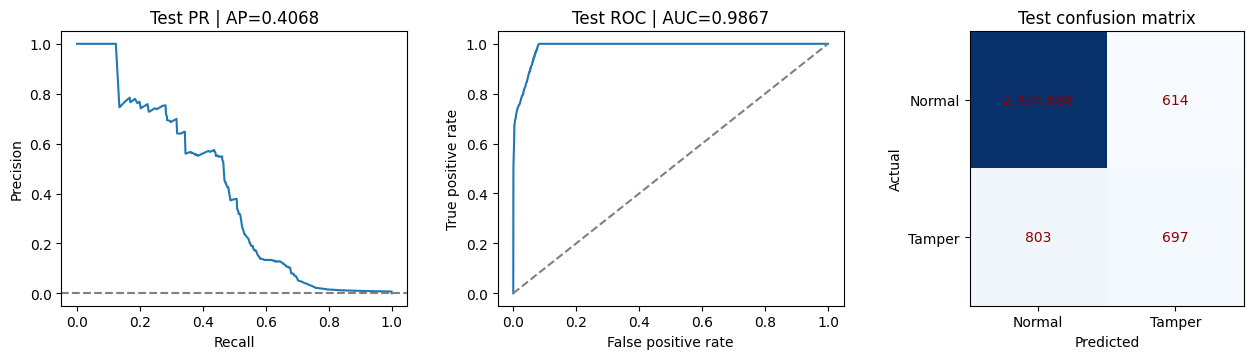

# 최종 실험 결과 (실행으로 생성)
- 학습: 99,998행, 116명. 전체 train 사용자 모두를 학습한 모델은 아님.
- 검증: 2,411,948행 / 2,443명. 테스트: 2,436,782행 / 2,444명.
- 학습/검증/테스트 사용자 교차 없음. 각 split 합성 변조: 등급+무기 1000건, 캐릭터명 500건.
- 검증 F1로 선택한 고정 임계값: 0.94074357.
- 테스트 Precision=0.531655, Recall=0.464667, F1=0.495909.
- 테스트 AP=0.406844, PR-AUC(사다리꼴)=0.406962, ROC-AUC=0.986716.
- 정상 오탐: 614건 / FPR=0.00025213.
- 학습 시간: 10.55초. 테스트 예측 시간: 43.20초.
- 주요 지표의 사용자 단위 95% CI: test_user_bootstrap_ci95.csv. AP/ROC-AUC의 CI 및 재학습 변동성은 계산하지 않음.

## 논문 해석 범위
원본은 검증된 정상 로그가 아니라 정상 후보이다. 양성 라벨은 두 유형의 합성 변조이며 실제 공격 정답 데이터가 아니다.
테스트 변조 비율은 실험자가 정한 값이므로 정밀도/AP를 실제 서비스 성능으로 일반화할 수 없다.
특히 이름만 바뀐 기록이 정상 획득과 동일한 관측 특징을 갖는다면 탐지할 수 없으며, 유형별 재현율을 반드시 보고한다.
테스트는 이 고정 실험의 최종 평가이다. 결과 확인 후 같은 테스트로 튜닝하면 독립 최종 평가로 주장할 수 없다.
단일 학습 시드 실험이다. 사용자 부트스트랩 CI는 고정 모델·합성 방식 조건의 표본 불확실성만 나타낸다.
공시 확률 분석은 01번 결과를 별도로 사용한다. 확률 조작 입증이나 변조 예방·암호학적 무결성 보장은 수행하지 않는다.
초기 계획서의 웹 대시보드, 비용 시뮬레이션, 레코드 해시 검증은 이 두 노트북의 구현 범위에 포함되지 않는다.

모델·성능표·그래프 저장 완료: /content/drive/MyDrive/캡스톤 2/ca

0

In [8]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,3,figsize=(13,3.7))
y=test_scores['label'].to_numpy();p=test_scores['score'].to_numpy()
pr,re,_=precision_recall_curve(y,p)
fpr,tpr,_=roc_curve(y,p)
# 브라우저 출력과 SVG 크기를 제한하되 지표 자체는 전체 데이터로 계산합니다.
def curve_points(x,y,limit=2000):
    ix=np.unique(np.linspace(0,len(x)-1,min(limit,len(x))).astype(int));return x[ix],y[ix]
axes[0].plot(*curve_points(re,pr));axes[0].axhline(y.mean(),ls='--',color='gray')
axes[0].set(xlabel='Recall',ylabel='Precision',title=f"Test PR | AP={final['average_precision_AP']:.4f}")
axes[1].plot(*curve_points(fpr,tpr));axes[1].plot([0,1],[0,1],'--',color='gray')
axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title=f"Test ROC | AUC={final['ROC_AUC']:.4f}")
cmat=np.array([[final['tn'],final['fp']],[final['fn'],final['tp']]])
axes[2].imshow(np.log1p(cmat),cmap='Blues')
for (i,j),v in np.ndenumerate(cmat):axes[2].text(j,i,f'{v:,}',ha='center',va='center',color='darkred')
axes[2].set(xticks=[0,1],yticks=[0,1],xticklabels=['Normal','Tamper'],yticklabels=['Normal','Tamper'],xlabel='Predicted',ylabel='Actual',title='Test confusion matrix')
fig.tight_layout();fig.savefig(RUN/'test_evaluation.png',dpi=200);fig.savefig(RUN/'test_evaluation.svg')
plt.show();plt.close(fig)
# 저장 파일을 다시 불러와 예측이 재현되는지 작은 테스트 입력에서 확인합니다.
reloaded=joblib.load(RUN/'random_forest_pipeline.joblib')
raw=pd.read_parquet(next(iter(sorted(test_root.glob('bucket-*.parquet')))),columns=RAW)
check=prepare_history(raw,pd.DataFrame(columns=RAW+['tamper_type'])).head(100)
assert np.allclose(model.predict_proba(check[FEATURES]),reloaded.predict_proba(check[FEATURES]))
summary=f'''# 최종 실험 결과 (실행으로 생성)
- 학습: {train_summary['rows']:,}행, {train_summary['users']}명. 전체 train 사용자 모두를 학습한 모델은 아님.
- 검증: {len(val_scores):,}행 / {len(sets['val']):,}명. 테스트: {len(test_scores):,}행 / {len(sets['test']):,}명.
- 학습/검증/테스트 사용자 교차 없음. 각 split 합성 변조: 등급+무기 {N_RANK}건, 캐릭터명 {N_CHARACTER}건.
- 검증 F1로 선택한 고정 임계값: {THRESHOLD:.8f}.
- 테스트 Precision={final['precision']:.6f}, Recall={final['recall']:.6f}, F1={final['f1']:.6f}.
- 테스트 AP={final['average_precision_AP']:.6f}, PR-AUC(사다리꼴)={final['PR_AUC_trapezoid']:.6f}, ROC-AUC={final['ROC_AUC']:.6f}.
- 정상 오탐: {final['fp']:,}건 / FPR={final['false_positive_rate']:.8f}.
- 학습 시간: {training_seconds:.2f}초. 테스트 예측 시간: {test_timing['predict_seconds']:.2f}초.
- 주요 지표의 사용자 단위 95% CI: test_user_bootstrap_ci95.csv. AP/ROC-AUC의 CI 및 재학습 변동성은 계산하지 않음.

## 논문 해석 범위
원본은 검증된 정상 로그가 아니라 정상 후보이다. 양성 라벨은 두 유형의 합성 변조이며 실제 공격 정답 데이터가 아니다.
테스트 변조 비율은 실험자가 정한 값이므로 정밀도/AP를 실제 서비스 성능으로 일반화할 수 없다.
특히 이름만 바뀐 기록이 정상 획득과 동일한 관측 특징을 갖는다면 탐지할 수 없으며, 유형별 재현율을 반드시 보고한다.
테스트는 이 고정 실험의 최종 평가이다. 결과 확인 후 같은 테스트로 튜닝하면 독립 최종 평가로 주장할 수 없다.
단일 학습 시드 실험이다. 사용자 부트스트랩 CI는 고정 모델·합성 방식 조건의 표본 불확실성만 나타낸다.
공시 확률 분석은 01번 결과를 별도로 사용한다. 확률 조작 입증이나 변조 예방·암호학적 무결성 보장은 수행하지 않는다.
초기 계획서의 웹 대시보드, 비용 시뮬레이션, 레코드 해시 검증은 이 두 노트북의 구현 범위에 포함되지 않는다.
'''
(RUN/'paper_results_summary.md').write_text(summary,encoding='utf-8')
assert all((RUN/f).exists() for f in ['performance_metrics.csv','test_user_bootstrap_ci95.csv','random_forest_pipeline.joblib','decision_threshold.json','paper_results_summary.md'])
# 노트북 밖에서 불러올 때도 전처리 사양과 임계값을 함께 사용해야 합니다.
joblib.dump({'pipeline':reloaded,'threshold':THRESHOLD,'features':FEATURES,'name_map':NAME_MAP,
             'banner_map':BANNER,'time_diff_group':['user_id','banner_group'],
             'feature_spec_file':'feature_spec.json'},RUN/'final_model_bundle.joblib',compress=3)
print(summary)
print('모델·성능표·그래프 저장 완료:',RUN)
del raw,check,reloaded;gc.collect()


## 검증 범위와 제출 시 주의
이 파일은 코드 문법·노트북 형식 검사와 작은 합성 자료의 전체 실행 시험을 통과한 구성입니다.
첨부물에는 실제 Parquet 데이터가 없어 실제 데이터의 학습·성능 측정은 실행하지 않았습니다. 저장된 셀 출력은 모두 비워 두었습니다.
**논문에는 본인 Colab에서 생성된 수치만 사용하세요.**

원본 노트북의 실행 결과에서 학습 시간차 결측 383건은 사용자+배너 기준과 일치했고, 검증은 사용자 기준으로 2,443건이었습니다. 이를 동일 함수로 교정하고 재학습합니다.
공시 확률 1.60% / 1.85% / 1.60%는 제공된 기존 코드의 2021~2022년 비교 기준을 승계한 값입니다. 이번에 공식 자료를 새로 검증한 값은 아니므로 논문에 당시 공식 상세 화면/보관 자료를 인용해야 합니다.

최초 제출 계획서와의 관계: 이번 결과는 전처리·통계 분석·합성 변조 탐지·성능 평가에 해당합니다.
계획서의 웹 대시보드, 지출 시뮬레이션, 레코드 해시 기반 무결성 검사는 구현 완료로 주장하지 않습니다.
단일 시드 결과이며, 사용자 부트스트랩 CI는 모델 재학습 변동성이나 실제 공격의 다양성을 반영하지 않습니다.
오탐이 0인 표본에서 부트스트랩 FPR 구간이 0으로 나오더라도 실제 오탐 위험이 0이라는 뜻은 아닙니다.
